# ApexPlanet Internship — Task 1
## Foundational Setup & Exploratory Data Analysis (EDA)

**Dataset:** Sample Superstore Sales  
**Objective:** Set up the Python environment, clean the dataset, perform exploratory data analysis, create visualizations, and document five evidence-based insights.

> Run the notebook from top to bottom. The first data-loading cell downloads the CSV into `data/raw/`. If the download is unavailable, download the Sample Superstore CSV manually and save it as `data/raw/sample_superstore.csv`.

## 1. Import libraries

Required libraries from the internship brief: `pandas`, `numpy`, `matplotlib`, `seaborn`, `plotly`, and `sqlalchemy`.

In [66]:
import warnings
warnings.filterwarnings("ignore")

from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.express as px

pd.set_option("display.max_columns", None)
pd.set_option("display.float_format", lambda x: f"{x:,.2f}")
sns.set_theme(style="whitegrid")

PROJECT_ROOT = Path.cwd()
# If notebook is opened from another directory, locate the project folder.
if not (PROJECT_ROOT / "data").exists() and (PROJECT_ROOT.parent / "data").exists():
    PROJECT_ROOT = PROJECT_ROOT.parent

RAW_DIR = PROJECT_ROOT / "data" / "raw"
PROCESSED_DIR = PROJECT_ROOT / "data" / "processed"
REPORTS_DIR = PROJECT_ROOT / "reports"
for folder in [RAW_DIR, PROCESSED_DIR, REPORTS_DIR]:
    folder.mkdir(parents=True, exist_ok=True)

print("Project folder:", PROJECT_ROOT.resolve())

Project folder: C:\Users\lenovo\Downloads\ApexPlanet Tasks\apexplanet-data-analytics


## 2. Download and load the dataset

This project uses Sample Superstore Sales, one of the dataset options named in the ApexPlanet brief. The source CSV contains order, customer, product, geography, sales, quantity, discount, and profit fields.

In [67]:

DATA_URL = "https://gist.githubusercontent.com/SharmaAshwini/8bd642f6c46792a9c40c8ccad60391e9/raw/4fd45d58a0a81c69814d270d7658f5e2a2d81154/Sample_Superstore.csv"

RAW_FILE = RAW_DIR / "sample_superstore.csv"

df_raw = pd.read_csv(DATA_URL, encoding="latin-1")

df_raw.to_csv(RAW_FILE, index=False)

print("Dataset downloaded successfully!")
print("Raw dataset shape:", df_raw.shape)

display(df_raw.head())


Dataset downloaded successfully!
Raw dataset shape: (9994, 21)


,Row ID,Order ID,Order Date,Ship Date,Ship Mode,Customer ID,Customer Name,Segment,Country,City,State,Postal Code,Region,Product ID,Category,Sub-Category,Product Name,Sales,Quantity,Discount,Profit
0,1,CA-2016-152156,08/11/16,11/11/16,Second Class,CG-12520,Claire Gute,Consumer,United States,Henderson,Kentucky,42420,South,FUR-BO-10001798,Furniture,Bookcases,Bush Somerset Collection Bookcase,261.96,2,0.00,41.91
1,2,CA-2016-152156,08/11/16,11/11/16,Second Class,CG-12520,Claire Gute,Consumer,United States,Henderson,Kentucky,42420,South,FUR-CH-10000454,Furniture,Chairs,"Hon Deluxe Fabric Upholstered Stacking Chairs,...",731.94,3,0.00,219.58
2,3,CA-2016-138688,12/06/16,16/06/16,Second Class,DV-13045,Darrin Van Huff,Corporate,United States,Los Angeles,California,90036,West,OFF-LA-10000240,Office Supplies,Labels,Self-Adhesive Address Labels for Typewriters b...,14.62,2,0.00,6.87
3,4,US-2015-108966,11/10/15,18/10/15,Standard Class,SO-20335,Sean O'Donnell,Consumer,United States,Fort Lauderdale,Florida,33311,South,FUR-TA-10000577,Furniture,Tables,Bretford CR4500 Series Slim Rectangular Table,957.58,5,0.45,-383.03
4,5,US-2015-108966,11/10/15,18/10/15,Standard Class,SO-20335,Sean O'Donnell,Consumer,United States,Fort Lauderdale,Florida,33311,South,OFF-ST-10000760,Office Supplies,Storage,Eldon Fold 'N Roll Cart System,22.37,2,0.20,2.52


## 3. Initial data inspection

Check column names, data types, missing values, duplicate rows, and statistical summaries before cleaning.

In [68]:
print("Dataset information:")
df_raw.info()

print("\nMissing values by column:")
display(df_raw.isna().sum().sort_values(ascending=False).to_frame("missing_values"))

print("\nDuplicate rows:", df_raw.duplicated().sum())

print("\nStatistical summary:")
display(df_raw.describe(include="all").T)

Dataset information:
<class 'pandas.DataFrame'>
RangeIndex: 9994 entries, 0 to 9993
Data columns (total 21 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Row ID         9994 non-null   int64  
 1   Order ID       9994 non-null   str    
 2   Order Date     9994 non-null   str    
 3   Ship Date      9994 non-null   str    
 4   Ship Mode      9994 non-null   str    
 5   Customer ID    9994 non-null   str    
 6   Customer Name  9994 non-null   str    
 7   Segment        9994 non-null   str    
 8   Country        9994 non-null   str    
 9   City           9994 non-null   str    
 10  State          9994 non-null   str    
 11  Postal Code    9994 non-null   int64  
 12  Region         9994 non-null   str    
 13  Product ID     9994 non-null   str    
 14  Category       9994 non-null   str    
 15  Sub-Category   9994 non-null   str    
 16  Product Name   9994 non-null   str    
 17  Sales          9994 non-null   float64
 18

,missing_values
Row ID,0
Order ID,0
Order Date,0
Ship Date,0
Ship Mode,0
Customer ID,0
Customer Name,0
Segment,0
Country,0
City,0



Duplicate rows: 0

Statistical summary:


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
Row ID,"9,994.00",NaN,NaN,NaN,"4,997.50","2,885.16",1.00,"2,499.25","4,997.50","7,495.75","9,994.00"
Order ID,9994,5009,CA-2017-100111,14,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Order Date,9994,1237,05/09/16,38,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Ship Date,9994,1334,16/12/15,35,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Ship Mode,9994,4,Standard Class,5968,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Customer ID,9994,793,WB-21850,37,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Customer Name,9994,793,William Brown,37,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Segment,9994,3,Consumer,5191,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Country,9994,1,United States,9994,NaN,NaN,NaN,NaN,NaN,NaN,NaN
City,9994,531,New York City,915,NaN,NaN,NaN,NaN,NaN,NaN,NaN


## 4. Data cleaning

Cleaning steps:
- Standardize column names.
- Remove exact duplicate records.
- Convert order and shipping dates to datetime.
- Convert numeric columns to numeric types.
- Fill missing numeric values with the median and categorical values with the mode.
- Remove rows where the order date is missing because they cannot be used for time-based analysis.
- Detect outliers using the IQR method and cap extreme numeric values at the IQR boundaries. The original raw CSV remains unchanged.

In [69]:
df = df_raw.copy()

# Standardize column names
df.columns = (
    df.columns.str.strip()
    .str.lower()
    .str.replace(r"[^a-z0-9]+", "_", regex=True)
    .str.strip("_")
)

# Remove exact duplicate rows
before_duplicates = len(df)
df = df.drop_duplicates().copy()
duplicates_removed = before_duplicates - len(df)

# Convert date columns
for col in ["order_date", "ship_date"]:
    if col in df.columns:
        df[col] = pd.to_datetime(df[col], errors="coerce")

# Convert numeric columns where present
numeric_candidates = ["sales", "quantity", "discount", "profit", "postal_code"]
for col in numeric_candidates:
    if col in df.columns:
        df[col] = pd.to_numeric(df[col], errors="coerce")

# Remove rows without an order date, if that column exists
if "order_date" in df.columns:
    rows_before_date_drop = len(df)
    df = df.dropna(subset=["order_date"]).copy()
    missing_order_dates_removed = rows_before_date_drop - len(df)
else:
    missing_order_dates_removed = 0

# Fill missing values
numeric_cols = df.select_dtypes(include=np.number).columns.tolist()
categorical_cols = df.select_dtypes(include=["object", "category", "str"]).columns.tolist()

for col in numeric_cols:
    if df[col].isna().any():
        df[col] = df[col].fillna(df[col].median())

for col in categorical_cols:
    if df[col].isna().any():
        mode_values = df[col].mode(dropna=True)
        if not mode_values.empty:
            df[col] = df[col].fillna(mode_values.iloc[0])
        else:
            df[col] = df[col].fillna("Unknown")

# IQR outlier detection and capping for analytical numeric measures
outlier_summary = []
for col in [c for c in ["sales", "quantity", "discount", "profit"] if c in df.columns]:
    q1 = df[col].quantile(0.25)
    q3 = df[col].quantile(0.75)
    iqr = q3 - q1
    lower = q1 - 1.5 * iqr
    upper = q3 + 1.5 * iqr
    outlier_count = int(((df[col] < lower) | (df[col] > upper)).sum())
    df[col] = df[col].clip(lower=lower, upper=upper)
    outlier_summary.append({
        "column": col, "lower_bound": lower, "upper_bound": upper,
        "outliers_capped": outlier_count
    })

# Helpful date features for EDA
if "order_date" in df.columns:
    df["order_year"] = df["order_date"].dt.year
    df["order_month"] = df["order_date"].dt.to_period("M").astype(str)

# Save cleaned data
CLEAN_FILE = PROCESSED_DIR / "superstore_cleaned.csv"
df.to_csv(CLEAN_FILE, index=False)

print("Duplicates removed:", duplicates_removed)
print("Rows removed due to missing order date:", missing_order_dates_removed)
display(pd.DataFrame(outlier_summary))
print("Cleaned dataset shape:", df.shape)
print("Remaining missing values:", int(df.isna().sum().sum()))
print("Cleaned dataset saved to:", CLEAN_FILE)
display(df.head())

Duplicates removed: 0
Rows removed due to missing order date: 0


,column,lower_bound,upper_bound,outliers_capped
0,sales,-271.71,498.93,1167
1,quantity,-2.50,9.50,170
2,discount,-0.30,0.50,856
3,profit,-39.72,70.82,1881


Cleaned dataset shape: (9994, 23)
Remaining missing values: 0
Cleaned dataset saved to: c:\Users\lenovo\Downloads\ApexPlanet Tasks\apexplanet-data-analytics\data\processed\superstore_cleaned.csv


,row_id,order_id,order_date,ship_date,ship_mode,customer_id,customer_name,segment,country,city,state,postal_code,region,product_id,category,sub_category,product_name,sales,quantity,discount,profit,order_year,order_month
0,1,CA-2016-152156,2016-08-11,2016-11-11,Second Class,CG-12520,Claire Gute,Consumer,United States,Henderson,Kentucky,42420,South,FUR-BO-10001798,Furniture,Bookcases,Bush Somerset Collection Bookcase,261.96,2.00,0.00,41.91,2016,2016-08
1,2,CA-2016-152156,2016-08-11,2016-11-11,Second Class,CG-12520,Claire Gute,Consumer,United States,Henderson,Kentucky,42420,South,FUR-CH-10000454,Furniture,Chairs,"Hon Deluxe Fabric Upholstered Stacking Chairs,...",498.93,3.00,0.00,70.82,2016,2016-08
2,3,CA-2016-138688,2016-12-06,2016-06-16,Second Class,DV-13045,Darrin Van Huff,Corporate,United States,Los Angeles,California,90036,West,OFF-LA-10000240,Office Supplies,Labels,Self-Adhesive Address Labels for Typewriters b...,14.62,2.00,0.00,6.87,2016,2016-12
3,4,US-2015-108966,2015-11-10,2015-10-18,Standard Class,SO-20335,Sean O'Donnell,Consumer,United States,Fort Lauderdale,Florida,33311,South,FUR-TA-10000577,Furniture,Tables,Bretford CR4500 Series Slim Rectangular Table,498.93,5.00,0.45,-39.72,2015,2015-11
4,5,US-2015-108966,2015-11-10,2015-10-18,Standard Class,SO-20335,Sean O'Donnell,Consumer,United States,Fort Lauderdale,Florida,33311,South,OFF-ST-10000760,Office Supplies,Storage,Eldon Fold 'N Roll Cart System,22.37,2.00,0.20,2.52,2015,2015-11


## 5. Verify the cleaned dataset

Confirm that data types are correct and that missing values and duplicates have been addressed.

In [70]:
df.info()
display(df.isna().sum().to_frame("missing_after_cleaning"))
print("Duplicate rows after cleaning:", df.duplicated().sum())
display(df.describe().T)

<class 'pandas.DataFrame'>
RangeIndex: 9994 entries, 0 to 9993
Data columns (total 23 columns):
 #   Column         Non-Null Count  Dtype         
---  ------         --------------  -----         
 0   row_id         9994 non-null   int64         
 1   order_id       9994 non-null   str           
 2   order_date     9994 non-null   datetime64[us]
 3   ship_date      9994 non-null   datetime64[us]
 4   ship_mode      9994 non-null   str           
 5   customer_id    9994 non-null   str           
 6   customer_name  9994 non-null   str           
 7   segment        9994 non-null   str           
 8   country        9994 non-null   str           
 9   city           9994 non-null   str           
 10  state          9994 non-null   str           
 11  postal_code    9994 non-null   int64         
 12  region         9994 non-null   str           
 13  product_id     9994 non-null   str           
 14  category       9994 non-null   str           
 15  sub_category   9994 non-null   s

,missing_after_cleaning
row_id,0
order_id,0
order_date,0
ship_date,0
ship_mode,0
customer_id,0
customer_name,0
segment,0
country,0
city,0


Duplicate rows after cleaning: 0


,count,mean,min,25%,50%,75%,max,std
row_id,"9,994.00","4,997.50",1.00,"2,499.25","4,997.50","7,495.75","9,994.00","2,885.16"
order_date,9994,2016-04-11 07:17:44.078447,2014-01-02 00:00:00,2015-05-01 00:00:00,2016-05-30 00:00:00,2017-04-09 00:00:00,2017-12-30 00:00:00,NaN
ship_date,9994,2016-04-20 15:38:17.458475,2014-01-04 00:00:00,2015-05-07 00:00:00,2016-06-12 00:00:00,2017-04-29 00:00:00,2018-05-01 00:00:00,NaN
postal_code,"9,994.00","55,190.38","1,040.00","23,223.00","56,430.50","90,008.00","99,301.00","32,063.69"
sales,"9,994.00",140.28,0.44,17.28,54.49,209.94,498.93,168.80
quantity,"9,994.00",3.75,1.00,2.00,3.00,5.00,9.50,2.10
discount,"9,994.00",0.14,0.00,0.00,0.20,0.20,0.50,0.16
profit,"9,994.00",16.07,-39.72,1.73,8.67,29.36,70.82,29.49
order_year,"9,994.00","2,015.72","2,014.00","2,015.00","2,016.00","2,017.00","2,017.00",1.12


## 6. Exploratory Data Analysis (EDA)

### 6.1 Overall business summary

In [71]:
summary = {}
if "sales" in df.columns:
    summary["Total Sales"] = df["sales"].sum()
if "profit" in df.columns:
    summary["Total Profit"] = df["profit"].sum()
if "quantity" in df.columns:
    summary["Total Quantity"] = df["quantity"].sum()
if "order_id" in df.columns:
    summary["Unique Orders"] = df["order_id"].nunique()
if "customer_id" in df.columns:
    summary["Unique Customers"] = df["customer_id"].nunique()

display(pd.DataFrame(summary.items(), columns=["Metric", "Value"]))

,Metric,Value
0,Total Sales,"1,401,969.37"
1,Total Profit,"160,583.73"
2,Total Quantity,"37,511.00"
3,Unique Orders,"5,009.00"
4,Unique Customers,793.00


### 6.2 Histograms — numerical distributions

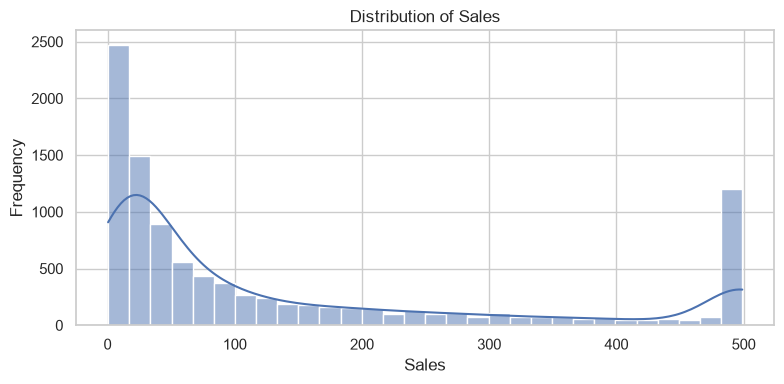

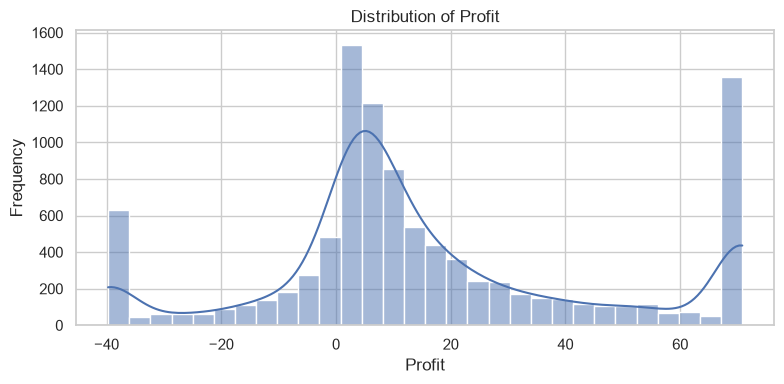

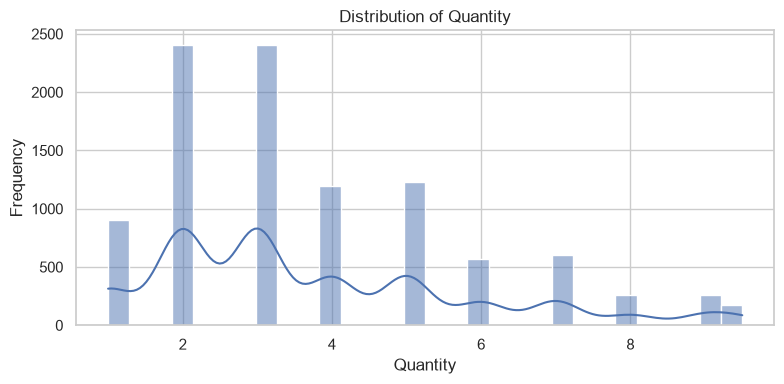

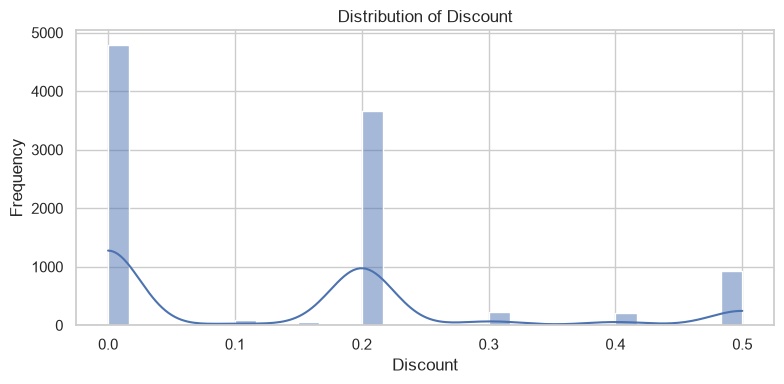

In [72]:
hist_cols = [c for c in ["sales", "profit", "quantity", "discount"] if c in df.columns]
for col in hist_cols:
    plt.figure(figsize=(8, 4))
    sns.histplot(df[col], bins=30, kde=True)
    plt.title(f"Distribution of {col.replace('_', ' ').title()}")
    plt.xlabel(col.replace("_", " ").title())
    plt.ylabel("Frequency")
    plt.tight_layout()
    plt.show()

### 6.3 Boxplots — spread and potential outliers

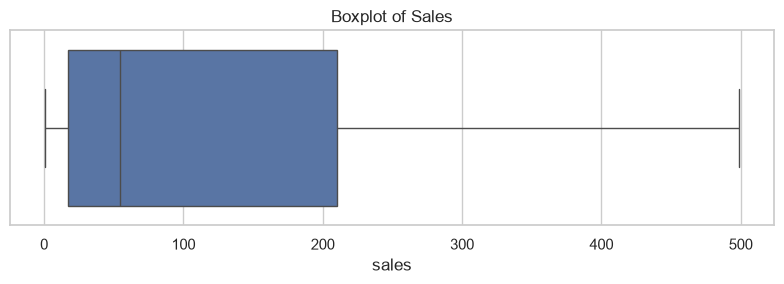

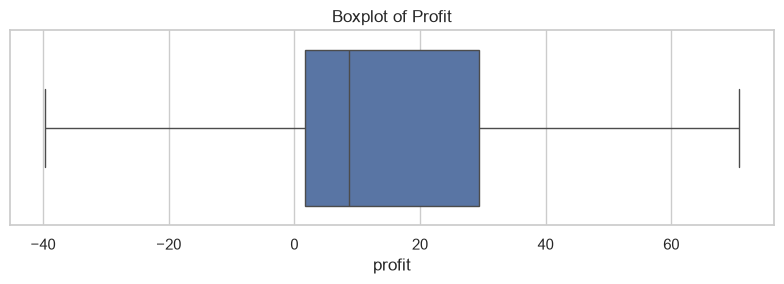

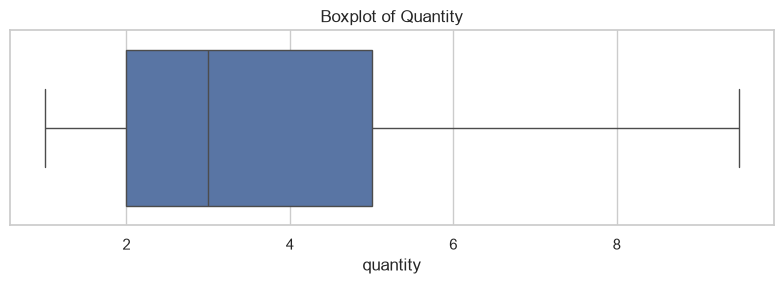

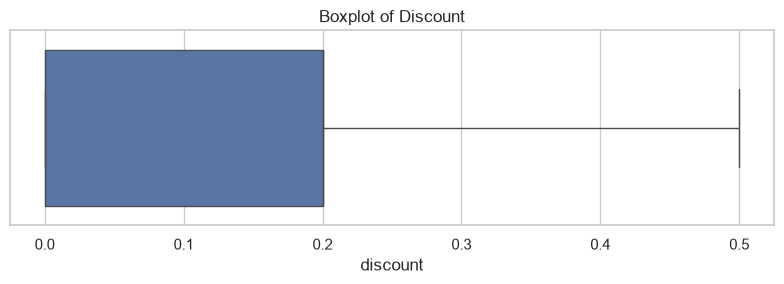

In [73]:
for col in hist_cols:
    plt.figure(figsize=(8, 3))
    sns.boxplot(x=df[col])
    plt.title(f"Boxplot of {col.replace('_', ' ').title()}")
    plt.tight_layout()
    plt.show()

### 6.4 Bar charts — category and regional comparisons

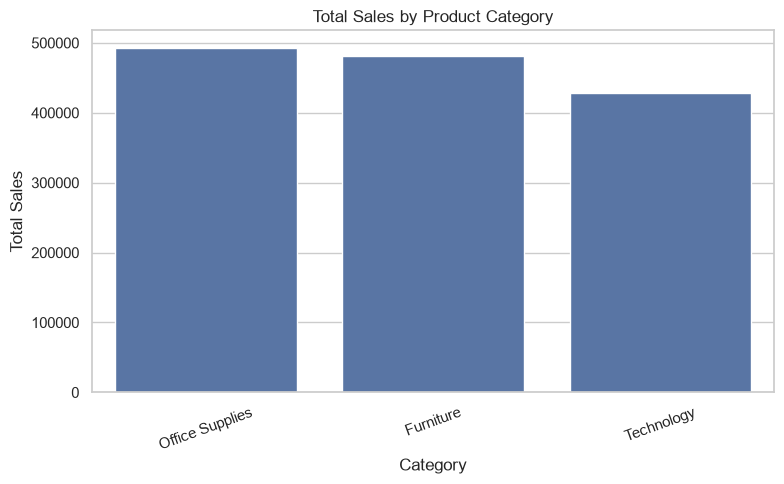

,category,sales
1,Office Supplies,"493,104.00"
0,Furniture,"480,878.01"
2,Technology,"427,987.35"


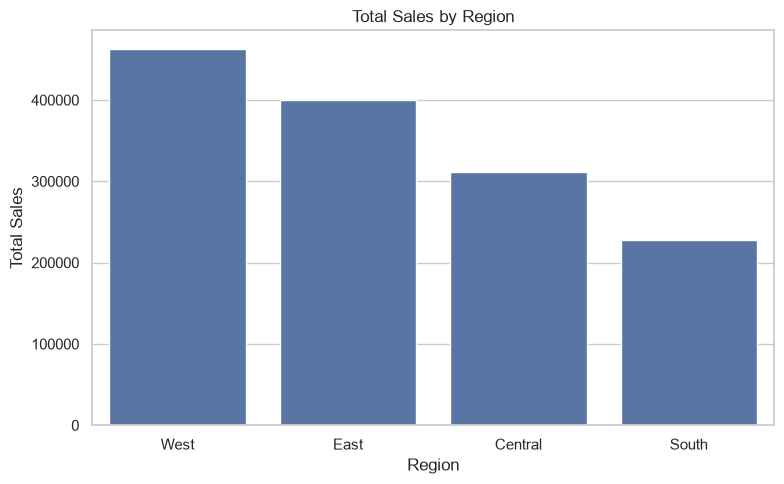

,region,sales
3,West,"462,410.08"
1,East,"399,530.10"
0,Central,"311,665.92"
2,South,"228,363.26"


In [74]:
if {"category", "sales"}.issubset(df.columns):
    category_sales = df.groupby("category", as_index=False)["sales"].sum().sort_values("sales", ascending=False)
    plt.figure(figsize=(8, 5))
    sns.barplot(data=category_sales, x="category", y="sales")
    plt.title("Total Sales by Product Category")
    plt.xlabel("Category")
    plt.ylabel("Total Sales")
    plt.xticks(rotation=20)
    plt.tight_layout()
    plt.show()
    display(category_sales)

if {"region", "sales"}.issubset(df.columns):
    region_sales = df.groupby("region", as_index=False)["sales"].sum().sort_values("sales", ascending=False)
    plt.figure(figsize=(8, 5))
    sns.barplot(data=region_sales, x="region", y="sales")
    plt.title("Total Sales by Region")
    plt.xlabel("Region")
    plt.ylabel("Total Sales")
    plt.tight_layout()
    plt.show()
    display(region_sales)

### 6.5 Correlation heatmap

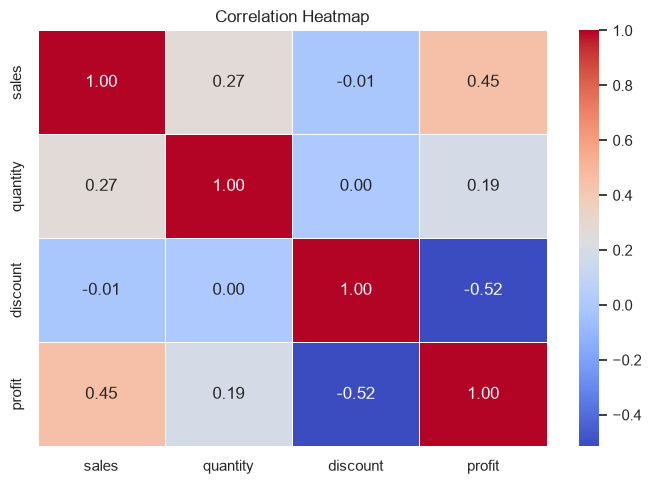

In [75]:
corr_cols = [c for c in ["sales", "quantity", "discount", "profit"] if c in df.columns]
if len(corr_cols) >= 2:
    plt.figure(figsize=(7, 5))
    sns.heatmap(df[corr_cols].corr(), annot=True, cmap="coolwarm", fmt=".2f", linewidths=0.5)
    plt.title("Correlation Heatmap")
    plt.tight_layout()
    plt.show()

### 6.6 Line chart — monthly sales trend

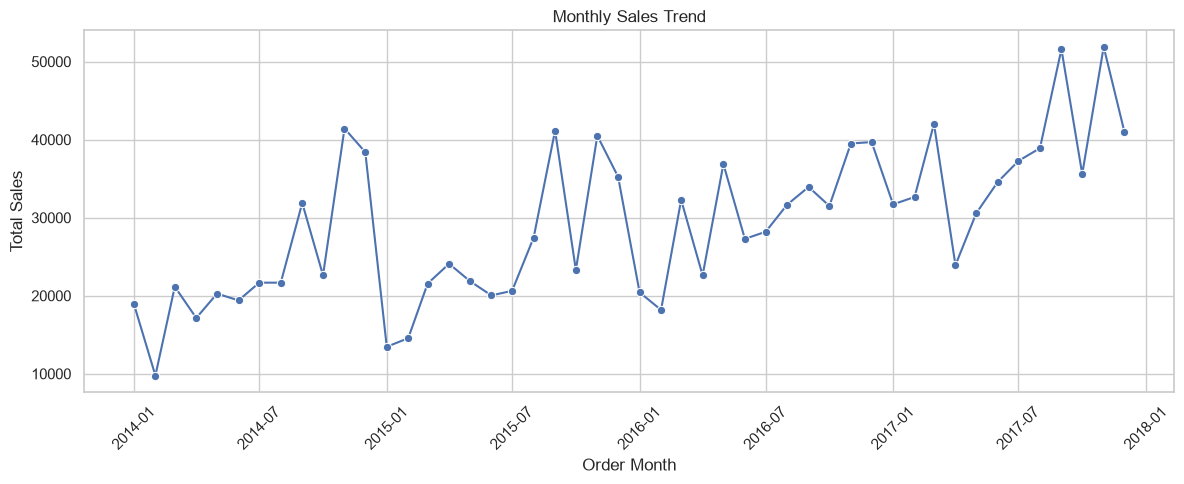

,order_date,sales
0,2014-01-01,"18,930.04"
1,2014-02-01,"9,769.81"
2,2014-03-01,"21,155.65"
3,2014-04-01,"17,148.47"
4,2014-05-01,"20,272.39"


In [76]:
if {"order_date", "sales"}.issubset(df.columns):
    monthly_sales = (
        df.set_index("order_date")["sales"]
        .resample("MS").sum()
        .reset_index()
    )
    plt.figure(figsize=(12, 5))
    sns.lineplot(data=monthly_sales, x="order_date", y="sales", marker="o")
    plt.title("Monthly Sales Trend")
    plt.xlabel("Order Month")
    plt.ylabel("Total Sales")
    plt.xticks(rotation=45)
    plt.tight_layout()
    plt.show()
    display(monthly_sales.head())

### 6.7 Optional interactive Plotly chart

In [77]:
if {"category", "sales", "profit"}.issubset(df.columns):
    interactive_data = df.groupby("category", as_index=False)[["sales", "profit"]].sum()
    fig = px.bar(
        interactive_data, x="category", y=["sales", "profit"],
        barmode="group", title="Interactive Sales and Profit by Category"
    )
    fig.show()

## 7. Five key insights

The following cells calculate findings from the cleaned data. Use the actual output values in your final report and LinkedIn post; do not copy example figures from another project.

In [78]:
insights = []

if {"category", "sales"}.issubset(df.columns):
    s = df.groupby("category")["sales"].sum()
    insights.append(f"Highest-sales category: {s.idxmax()} (sales = {s.max():,.2f}).")

if {"category", "profit"}.issubset(df.columns):
    p = df.groupby("category")["profit"].sum()
    insights.append(f"Highest-profit category: {p.idxmax()} (profit = {p.max():,.2f}).")

if {"region", "sales"}.issubset(df.columns):
    r = df.groupby("region")["sales"].sum()
    insights.append(f"Highest-sales region: {r.idxmax()} (sales = {r.max():,.2f}).")

if {"sub_category", "profit"}.issubset(df.columns):
    sub = df.groupby("sub_category")["profit"].sum()
    insights.append(f"Most profitable sub-category: {sub.idxmax()} (profit = {sub.max():,.2f}).")
    insights.append(f"Lowest-profit sub-category: {sub.idxmin()} (profit = {sub.min():,.2f}).")

if {"segment", "sales"}.issubset(df.columns):
    seg = df.groupby("segment")["sales"].sum()
    insights.append(f"Highest-sales customer segment: {seg.idxmax()} (sales = {seg.max():,.2f}).")

if {"order_date", "sales"}.issubset(df.columns):
    monthly = df.set_index("order_date")["sales"].resample("MS").sum()
    if len(monthly) > 0:
        insights.append(f"Best sales month in the dataset: {monthly.idxmax():%B %Y} (sales = {monthly.max():,.2f}).")

for number, insight in enumerate(insights[:5], start=1):
    print(f"{number}. {insight}")

if len(insights) < 5:
    print("Some expected columns are missing; review the available dataset columns before finalizing five insights.")

1. Highest-sales category: Office Supplies (sales = 493,104.00).
2. Highest-profit category: Office Supplies (profit = 81,562.11).
3. Highest-sales region: West (sales = 462,410.08).
4. Most profitable sub-category: Paper (profit = 28,480.99).
5. Lowest-profit sub-category: Tables (profit = -1,111.59).


## 8. Export EDA summary and final files

The cleaned CSV is saved in `data/processed/`. This cell also saves a compact text summary for the reports folder.

In [79]:
report_file = REPORTS_DIR / "eda_key_insights.txt"
with open(report_file, "w", encoding="utf-8") as file:
    file.write("APEXPLANET INTERNSHIP — TASK 1 EDA INSIGHTS\n")
    file.write("=" * 48 + "\n")
    for number, insight in enumerate(insights[:5], start=1):
        file.write(f"{number}. {insight}\n")

print("Cleaned dataset:", CLEAN_FILE.resolve())
print("Insights report:", report_file.resolve())

Cleaned dataset: C:\Users\lenovo\Downloads\ApexPlanet Tasks\apexplanet-data-analytics\data\processed\superstore_cleaned.csv
Insights report: C:\Users\lenovo\Downloads\ApexPlanet Tasks\apexplanet-data-analytics\reports\eda_key_insights.txt


In [80]:
print("Dataset shape:", df.shape)

print("\nUnique values:")
for col in df.select_dtypes(include="object").columns:
    print(col, ":", df[col].nunique())

print("\nNumerical summary:")
display(df.describe())

Dataset shape: (9994, 23)

Unique values:
order_id : 5009
ship_mode : 4
customer_id : 793
customer_name : 793
segment : 3
country : 1
city : 531
state : 49
region : 4
product_id : 1862
category : 3
sub_category : 17
product_name : 1850
order_month : 48

Numerical summary:


,row_id,order_date,ship_date,postal_code,sales,quantity,discount,profit,order_year
count,"9,994.00",9994,9994,"9,994.00","9,994.00","9,994.00","9,994.00","9,994.00","9,994.00"
mean,"4,997.50",2016-04-11 07:17:44.078447,2016-04-20 15:38:17.458475,"55,190.38",140.28,3.75,0.14,16.07,"2,015.72"
min,1.00,2014-01-02 00:00:00,2014-01-04 00:00:00,"1,040.00",0.44,1.00,0.00,-39.72,"2,014.00"
25%,"2,499.25",2015-05-01 00:00:00,2015-05-07 00:00:00,"23,223.00",17.28,2.00,0.00,1.73,"2,015.00"
50%,"4,997.50",2016-05-30 00:00:00,2016-06-12 00:00:00,"56,430.50",54.49,3.00,0.20,8.67,"2,016.00"
75%,"7,495.75",2017-04-09 00:00:00,2017-04-29 00:00:00,"90,008.00",209.94,5.00,0.20,29.36,"2,017.00"
max,"9,994.00",2017-12-30 00:00:00,2018-05-01 00:00:00,"99,301.00",498.93,9.50,0.50,70.82,"2,017.00"
std,"2,885.16",NaN,NaN,"32,063.69",168.80,2.10,0.16,29.49,1.12


In [81]:
print("Column names:")
print(df.columns.tolist())

print("\nFirst 5 rows:")
display(df.head())

print("\nDataset information:")
df.info()

Column names:
['row_id', 'order_id', 'order_date', 'ship_date', 'ship_mode', 'customer_id', 'customer_name', 'segment', 'country', 'city', 'state', 'postal_code', 'region', 'product_id', 'category', 'sub_category', 'product_name', 'sales', 'quantity', 'discount', 'profit', 'order_year', 'order_month']

First 5 rows:


,row_id,order_id,order_date,ship_date,ship_mode,customer_id,customer_name,segment,country,city,state,postal_code,region,product_id,category,sub_category,product_name,sales,quantity,discount,profit,order_year,order_month
0,1,CA-2016-152156,2016-08-11,2016-11-11,Second Class,CG-12520,Claire Gute,Consumer,United States,Henderson,Kentucky,42420,South,FUR-BO-10001798,Furniture,Bookcases,Bush Somerset Collection Bookcase,261.96,2.00,0.00,41.91,2016,2016-08
1,2,CA-2016-152156,2016-08-11,2016-11-11,Second Class,CG-12520,Claire Gute,Consumer,United States,Henderson,Kentucky,42420,South,FUR-CH-10000454,Furniture,Chairs,"Hon Deluxe Fabric Upholstered Stacking Chairs,...",498.93,3.00,0.00,70.82,2016,2016-08
2,3,CA-2016-138688,2016-12-06,2016-06-16,Second Class,DV-13045,Darrin Van Huff,Corporate,United States,Los Angeles,California,90036,West,OFF-LA-10000240,Office Supplies,Labels,Self-Adhesive Address Labels for Typewriters b...,14.62,2.00,0.00,6.87,2016,2016-12
3,4,US-2015-108966,2015-11-10,2015-10-18,Standard Class,SO-20335,Sean O'Donnell,Consumer,United States,Fort Lauderdale,Florida,33311,South,FUR-TA-10000577,Furniture,Tables,Bretford CR4500 Series Slim Rectangular Table,498.93,5.00,0.45,-39.72,2015,2015-11
4,5,US-2015-108966,2015-11-10,2015-10-18,Standard Class,SO-20335,Sean O'Donnell,Consumer,United States,Fort Lauderdale,Florida,33311,South,OFF-ST-10000760,Office Supplies,Storage,Eldon Fold 'N Roll Cart System,22.37,2.00,0.20,2.52,2015,2015-11



Dataset information:
<class 'pandas.DataFrame'>
RangeIndex: 9994 entries, 0 to 9993
Data columns (total 23 columns):
 #   Column         Non-Null Count  Dtype         
---  ------         --------------  -----         
 0   row_id         9994 non-null   int64         
 1   order_id       9994 non-null   str           
 2   order_date     9994 non-null   datetime64[us]
 3   ship_date      9994 non-null   datetime64[us]
 4   ship_mode      9994 non-null   str           
 5   customer_id    9994 non-null   str           
 6   customer_name  9994 non-null   str           
 7   segment        9994 non-null   str           
 8   country        9994 non-null   str           
 9   city           9994 non-null   str           
 10  state          9994 non-null   str           
 11  postal_code    9994 non-null   int64         
 12  region         9994 non-null   str           
 13  product_id     9994 non-null   str           
 14  category       9994 non-null   str           
 15  sub_catego

## 9. Task 1 completion checklist

- [ ] Python/Jupyter environment prepared
- [ ] Required libraries installed
- [ ] Raw dataset saved in `data/raw/`
- [ ] Missing values handled
- [ ] Duplicate rows removed
- [ ] Date and numeric data types corrected
- [ ] IQR outliers handled
- [ ] Cleaned dataset saved in `data/processed/`
- [ ] Statistical summary generated
- [ ] Histograms and boxplots created
- [ ] Bar charts created
- [ ] Correlation heatmap created
- [ ] Monthly sales line chart created (if date field is available)
- [ ] Five key insights documented
- [ ] Notebook and cleaned dataset uploaded to GitHub
- [ ] Screen recording uploaded to LinkedIn Featured section

**Important:** Run every cell successfully and check the generated insight values before recording your screen or publishing your LinkedIn post.